In [1]:
import pandas as pd
df = pd.read_csv("credit_card_fraud_drift_2026.csv")
df.head()


,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,...,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
0,TX4042000000000,CU00022008,CA000000001,ME000381,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
1,TX4042000000001,CU00000598,CA000000002,ME000764,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
2,TX4042000000002,CU00018179,CA000000003,ME001251,2026-01-01 00:03:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
3,TX4042000000003,CU00023636,CA000000004,ME002627,2026-01-01 00:04:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
4,TX4042000000004,CU00028521,CA000000005,ME004940,2026-01-01 00:05:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period


In [2]:
df.shape

(120000, 73)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 73 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   transaction_id                      120000 non-null  object 
 1   customer_id                         120000 non-null  object 
 2   card_id                             120000 non-null  object 
 3   merchant_id                         120000 non-null  object 
 4   transaction_datetime                120000 non-null  object 
 5   month                               120000 non-null  int64  
 6   week_of_year                        120000 non-null  int64  
 7   drift_phase                         120000 non-null  int64  
 8   days_into_phase                     120000 non-null  int64  
 9   drift_magnitude                     120000 non-null  float64
 10  transaction_amount                  120000 non-null  float64
 11  merchant_category         

In [4]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

dispute_delay_days        117307
dispute_event_datetime    117307
adjudication_datetime     117307
dtype: int64

In [5]:
df["dispute_filed"].value_counts(dropna=False)

dispute_filed
0    117307
1      2693
Name: count, dtype: int64

In [6]:
pd.crosstab(
    df["dispute_filed"],
    df["dispute_event_datetime"].isna(),
    colnames=["Dispute date is missing"]
)

Dispute date is missing,False,True
dispute_filed,,
0,0,117307
1,2693,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["transaction_datetime"] = pd.to_datetime(
    df["transaction_datetime"],
    errors="raise"
)

df["transaction_datetime"].dtype

dtype('<M8[ns]')

In [9]:
df["transaction_datetime"].agg(["min", "max"])

min   2026-01-01 00:00:00
max   2026-06-30 23:58:00
Name: transaction_datetime, dtype: datetime64[ns]

In [10]:
df["is_fraud"].value_counts()

is_fraud
0    108613
1     11387
Name: count, dtype: int64

In [11]:
df["is_fraud"].value_counts(normalize=True).mul(100).round(2)

is_fraud
0    90.51
1     9.49
Name: proportion, dtype: float64

In [12]:
df["fraud_type"].value_counts()

fraud_type
Legitimate            108613
Card-Not-Present        2879
Account-Takeover        2571
Synthetic-Identity      2146
Card-Present            1898
Friendly-Fraud          1893
Name: count, dtype: int64

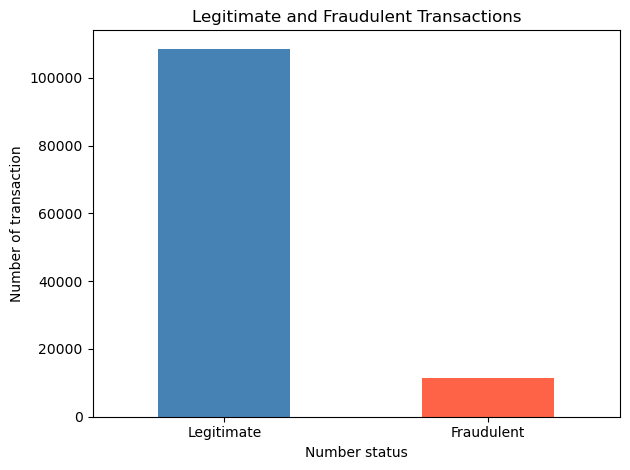

In [13]:
import matplotlib.pyplot as plt
counts = df["is_fraud"].value_counts().reindex([0,1])
counts.index = ["Legitimate", "Fraudulent" ]

counts.plot(kind="bar", color=["steelblue", "tomato"])

plt.title("Legitimate and Fraudulent Transactions")
plt.xlabel("Number status")
plt.ylabel("Number of transaction")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
df["transaction_amount"].describe().round(2)

count    120000.00
mean         46.33
std          36.97
min           1.50
25%          22.72
50%          36.29
75%          57.90
max        1030.59
Name: transaction_amount, dtype: float64

In [15]:
df.groupby("is_fraud")["transaction_amount"].agg(
    ["count", "mean", "median","std", "min","max"]
).round(2)

,count,mean,median,std,min,max
is_fraud,,,,,,
0,108613,43.89,34.87,33.78,1.50,853.06
1,11387,69.60,54.84,54.06,4.05,1030.59


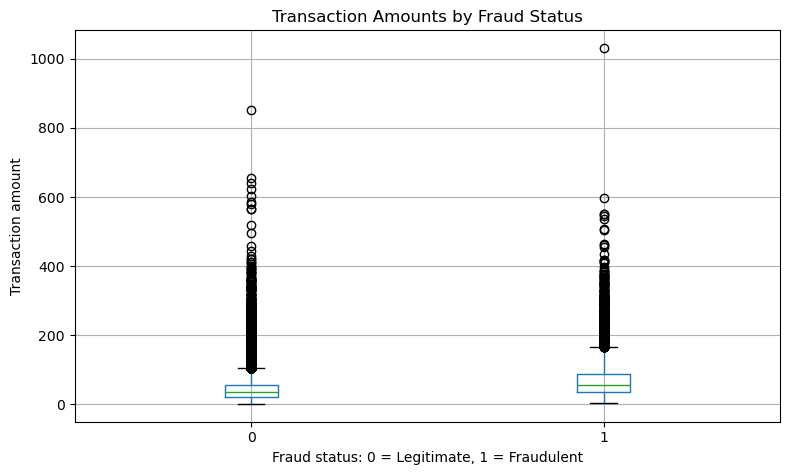

In [16]:
df.boxplot(column="transaction_amount", by="is_fraud", figsize=(8, 5))

plt.title("Transaction Amounts by Fraud Status")
plt.suptitle("")
plt.xlabel("Fraud status: 0 = Legitimate, 1 = Fraudulent")
plt.ylabel("Transaction amount")
plt.tight_layout()
plt.show()

In [17]:
q1 = df["transaction_amount"].quantile(0.25)
q3 = df["transaction_amount"].quantile(0.75)

iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

outliers = df[
    (df["transaction_amount"] < lower_limit)
    | (df["transaction_amount"] > upper_limit)
]

print("Lower limit:", round(lower_limit, 2))
print("Upper limit:", round(upper_limit, 2))
print("Potential outlier transactions:", len(outliers))

Lower limit: -30.05
Upper limit: 110.67
Potential outlier transactions: 6581


In [18]:
df.groupby(
    df["transaction_amount"] > upper_limit
)["is_fraud"].agg(["count", "mean"]).rename(
    index={False: "Other amounts", True: "High amount outliers"},
    columns={"count": "Transactions", "mean": "Fraud rate"}
).assign(
    **{"Fraud rate": lambda x: (x["Fraud rate"] * 100).round(2)}
)

,Transactions,Fraud rate
transaction_amount,,
Other amounts,113419,8.50
High amount outliers,6581,26.61


In [19]:
df["transaction_hour"] = df["transaction_datetime"].dt.hour
df["transaction_day_of_week"] = df["transaction_datetime"].dt.day_name()
df["month"] = df["transaction_datetime"].dt.month

df[
    ["transaction_datetime", "transaction_hour",
     "transaction_day_of_week", "month"]
].head()

,transaction_datetime,transaction_hour,transaction_day_of_week,month
0,2026-01-01 00:00:00,0,Thursday,1
1,2026-01-01 00:00:00,0,Thursday,1
2,2026-01-01 00:03:00,0,Thursday,1
3,2026-01-01 00:04:00,0,Thursday,1
4,2026-01-01 00:05:00,0,Thursday,1


In [20]:
monthly_summary = df.groupby("month").agg(
    total_transactions=("is_fraud", "size"),
    fraud_transactions=("is_fraud", "sum"),
    fraud_rate_percent=("is_fraud", "mean")
)

monthly_summary["fraud_rate_percent"] = (
    monthly_summary["fraud_rate_percent"] * 100
).round(2)

monthly_summary

,total_transactions,fraud_transactions,fraud_rate_percent
month,,,
1,20521,1909,9.30
2,18612,1808,9.71
3,20445,1905,9.32
4,19861,1870,9.42
5,20725,1979,9.55
6,19836,1916,9.66


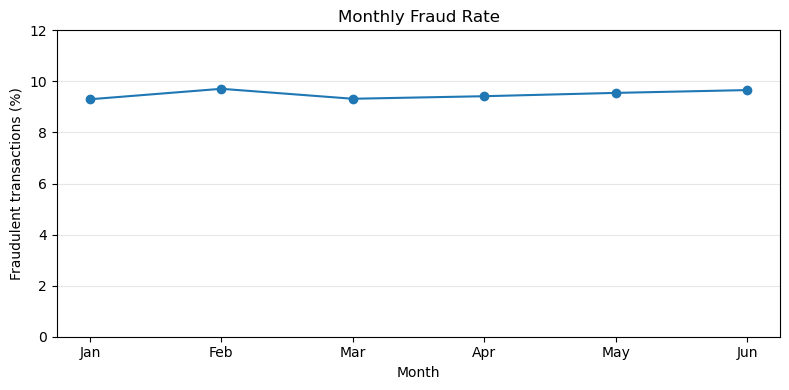

In [21]:
monthly_summary["fraud_rate_percent"].plot(
    kind="line",
    marker="o",
    figsize=(8,4)
)

plt.title("Monthly Fraud Rate")
plt.xlabel("Month")
plt.ylabel("Fraudulent transactions (%)")
plt.xticks([1,2,3,4,5,6], ["Jan", "Feb", "Mar","Apr","May","Jun"])
plt.ylim(0,12)
plt.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()

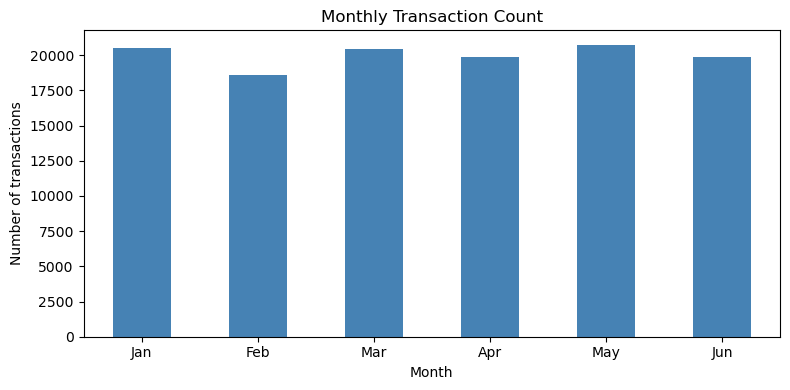

In [22]:
monthly_summary["total_transactions"].plot(
    kind="bar",
    figsize=(8, 4),
    color="steelblue"
)

plt.title("Monthly Transaction Count")
plt.xlabel("Month")
plt.ylabel("Number of transactions")
plt.xticks(
    range(6),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
    rotation=0
)
plt.tight_layout()
plt.show()


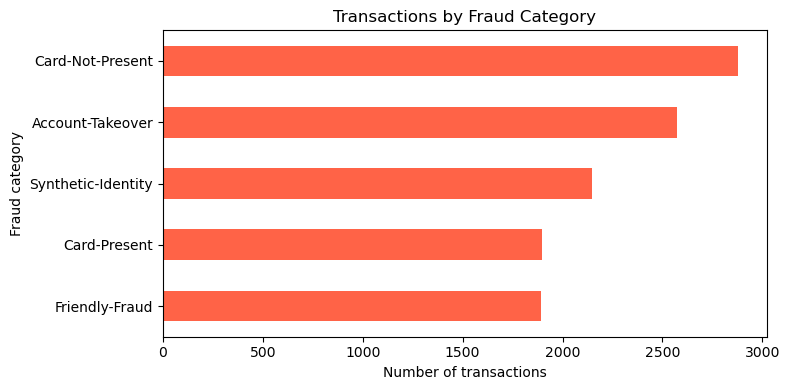

In [23]:
fraud_counts = df.loc[
    df["is_fraud"] == 1, "fraud_type"
].value_counts().sort_values()

fraud_counts.plot(
    kind="barh",
    figsize=(8, 4),
    color="tomato"
)

plt.title("Transactions by Fraud Category")
plt.xlabel("Number of transactions")
plt.ylabel("Fraud category")
plt.tight_layout()
plt.show()

In [24]:
hourly_summary = df.groupby("transaction_hour").agg(
    total_transactions=("is_fraud", "size"),
    fraud_transactions=("is_fraud", "sum"),
    fraud_rate_percent=("is_fraud", "mean")
)

hourly_summary["fraud_rate_percent"] = (
    hourly_summary["fraud_rate_percent"] * 100
).round(2)

hourly_summary

,total_transactions,fraud_transactions,fraud_rate_percent
transaction_hour,,,
0,5078,481,9.47
1,4974,532,10.70
2,5047,503,9.97
3,4915,473,9.62
4,5090,464,9.12
5,4950,471,9.52
6,5014,454,9.05
7,4999,462,9.24
8,5070,485,9.57


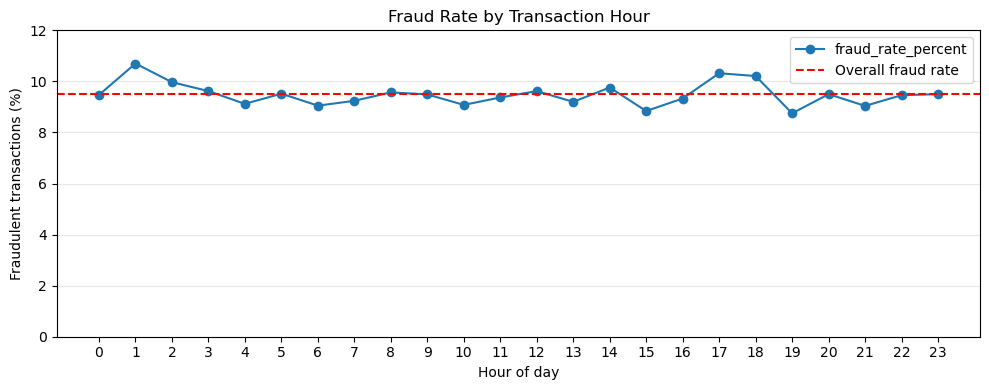

In [25]:
hourly_summary["fraud_rate_percent"].plot(
    kind="line",
    marker="o",
    figsize=(10, 4)
)

plt.axhline(
    df["is_fraud"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall fraud rate"
)

plt.title("Fraud Rate by Transaction Hour")
plt.xlabel("Hour of day")
plt.ylabel("Fraudulent transactions (%)")
plt.xticks(range(24))
plt.ylim(0, 12)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
df["transaction_id"].duplicated().sum()
(df["transaction_amount"] <= 0).sum()

np.int64(0)

In [27]:
pd.crosstab(df["fraud_type"], df["is_fraud"])

is_fraud,0,1
fraud_type,,
Account-Takeover,0,2571
Card-Not-Present,0,2879
Card-Present,0,1898
Friendly-Fraud,0,1893
Legitimate,108613,0
Synthetic-Identity,0,2146


In [28]:
df.groupby("drift_phase_name").agg(
    start_date=("transaction_datetime", "min"),
    end_date=("transaction_datetime", "max"),
    transactions=("is_fraud", "size")
).sort_values("start_date")

,start_date,end_date,transactions
drift_phase_name,,,
stable_training,2026-01-01 00:00:00,2026-02-28 23:59:00,39133
pre_drift_validation,2026-03-01 00:02:00,2026-03-31 23:58:00,20445
peak_drift,2026-04-01 00:04:00,2026-05-31 23:57:00,40586
partial_stabilization,2026-06-01 00:05:00,2026-06-30 23:58:00,19836


In [29]:
print(df.columns.tolist())

['transaction_id', 'customer_id', 'card_id', 'merchant_id', 'transaction_datetime', 'month', 'week_of_year', 'drift_phase', 'days_into_phase', 'drift_magnitude', 'transaction_amount', 'merchant_category', 'merchant_country', 'transaction_hour', 'transaction_day_of_week', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'email_domain', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', '

In [30]:
feature_columns = [
    "transaction_amount",
    "merchant_category",
    "merchant_country",
    "transaction_hour",
    "transaction_day_of_week",
    "card_present",
    "account_age_days",
    "credit_limit",
    "credit_score",
    "num_cards_held",
    "transactions_last_1h",
    "transactions_last_24h",
    "transactions_last_7d",
    "amount_last_1h",
    "amount_last_24h",
    "days_since_last_transaction",
    "distance_from_home_km",
    "distance_from_last_tx_km",
    "international_transaction",
    "high_risk_country",
    "amount_vs_avg_ratio",
    "used_chip",
    "used_pin",
    "transaction_channel",
    "device_type",
    "browser",
    "is_weekend",
    "avg_transaction_amount_30d",
    "std_transaction_amount_30d",
    "num_declined_last_30d",
    "num_chargebacks_ever",
    "failed_auth_attempts_24h",
    "device_change_7d",
    "billing_shipping_mismatch",
    "account_profile_change_7d",
    "merchant_velocity_24h",
    "prior_dispute_ratio_90d",
    "pos_entry_fallback",
    "pin_retry_count_24h"
]

print("Selected features:", len(feature_columns))

Selected features: 39


In [31]:
train_df = df[df["transaction_datetime"] < "2026-03-01"].copy()

validation_df = df[
    (df["transaction_datetime"] >= "2026-03-01")
    & (df["transaction_datetime"] < "2026-04-01")
].copy()

test_df = df[df["transaction_datetime"] >= "2026-04-01"].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Test rows:", len(test_df))

Training rows: 39133
Validation rows: 20445
Test rows: 60422


In [32]:
X_train = train_df[feature_columns].copy()
y_train = train_df["is_fraud"].copy()

X_validation = validation_df[feature_columns].copy()
y_validation = validation_df["is_fraud"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["is_fraud"].copy()

print("Training inputs:", X_train.shape)
print("Training target:", y_train.shape)

Training inputs: (39133, 39)
Training target: (39133,)


In [33]:
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numeric features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))
print("Categorical columns:", categorical_columns)

Numeric features: 33
Categorical features: 6
Categorical columns: ['merchant_category', 'merchant_country', 'transaction_day_of_week', 'transaction_channel', 'device_type', 'browser']


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

In [35]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [36]:
from sklearn.metrics import classification_report, confusion_matrix

validation_predictions = logistic_model.predict(X_validation)

print(classification_report(
    y_validation,
    validation_predictions,
    digits=3,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_validation, validation_predictions))

              precision    recall  f1-score   support

           0      0.997     0.998     0.998     18540
           1      0.985     0.967     0.976      1905

    accuracy                          0.996     20445
   macro avg      0.991     0.983     0.987     20445
weighted avg      0.996     0.996     0.996     20445

Confusion matrix:
[[18512    28]
 [   62  1843]]


In [37]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

model_results = [{
    "Model": "Logistic Regression",
    "Balancing": "None",
    "Accuracy": accuracy_score(y_validation, validation_predictions),
    "Precision": precision_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_validation, validation_predictions, zero_division=0
    )
}]

pd.DataFrame(model_results).round(4)

,Model,Balancing,Accuracy,Precision,Recall,F1
0,Logistic Regression,None,0.9956,0.985,0.9675,0.9762


In [38]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

tree_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


In [39]:
tree_predictions = tree_model.predict(X_validation)

print(classification_report(
    y_validation,
    tree_predictions,
    digits=3,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_validation, tree_predictions))

model_results = [
    result for result in model_results
    if result["Model"] != "Decision Tree"
]

model_results.append({
    "Model": "Decision Tree",
    "Balancing": "None",
    "Accuracy": accuracy_score(y_validation, tree_predictions),
    "Precision": precision_score(
        y_validation, tree_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_validation, tree_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_validation, tree_predictions, zero_division=0
    )
})

pd.DataFrame(model_results).round(4)

              precision    recall  f1-score   support

           0      0.999     1.000     1.000     18540
           1      0.997     0.993     0.995      1905

    accuracy                          0.999     20445
   macro avg      0.998     0.996     0.997     20445
weighted avg      0.999     0.999     0.999     20445

Confusion matrix:
[[18535     5]
 [   13  1892]]


,Model,Balancing,Accuracy,Precision,Recall,F1
0,Logistic Regression,None,0.9956,0.9850,0.9675,0.9762
1,Decision Tree,None,0.9991,0.9974,0.9932,0.9953


In [40]:
tree_predictions = tree_model.predict(X_validation)

print(classification_report(
    y_validation,
    tree_predictions,
    digits=3,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_validation, tree_predictions))

model_results = [
    result for result in model_results
    if result["Model"] != "Decision Tree"
]

model_results.append({
    "Model": "Decision Tree",
    "Balancing": "None",
    "Accuracy": accuracy_score(y_validation, tree_predictions),
    "Precision": precision_score(
        y_validation, tree_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_validation, tree_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_validation, tree_predictions, zero_division=0
    )
})

pd.DataFrame(model_results).round(4)

              precision    recall  f1-score   support

           0      0.999     1.000     1.000     18540
           1      0.997     0.993     0.995      1905

    accuracy                          0.999     20445
   macro avg      0.998     0.996     0.997     20445
weighted avg      0.999     0.999     0.999     20445

Confusion matrix:
[[18535     5]
 [   13  1892]]


,Model,Balancing,Accuracy,Precision,Recall,F1
0,Logistic Regression,None,0.9956,0.9850,0.9675,0.9762
1,Decision Tree,None,0.9991,0.9974,0.9932,0.9953


In [41]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [42]:
forest_predictions = forest_model.predict(X_validation)

print(classification_report(
    y_validation,
    forest_predictions,
    digits=3,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_validation, forest_predictions))

# Replace any previous entry so rerunning this cell is safe.
model_results = [
    result for result in model_results
    if result["Model"] != "Random Forest"
]

model_results.append({
    "Model": "Random Forest",
    "Balancing": "None",
    "Accuracy": accuracy_score(y_validation, forest_predictions),
    "Precision": precision_score(
        y_validation, forest_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_validation, forest_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_validation, forest_predictions, zero_division=0
    )
})

comparison = pd.DataFrame(model_results)
comparison.sort_values("F1", ascending=False).round(4)


              precision    recall  f1-score   support

           0      0.999     1.000     0.999     18540
           1      0.999     0.986     0.993      1905

    accuracy                          0.999     20445
   macro avg      0.999     0.993     0.996     20445
weighted avg      0.999     0.999     0.999     20445

Confusion matrix:
[[18539     1]
 [   27  1878]]


,Model,Balancing,Accuracy,Precision,Recall,F1
1,Decision Tree,None,0.9991,0.9974,0.9932,0.9953
2,Random Forest,None,0.9986,0.9995,0.9858,0.9926
0,Logistic Regression,None,0.9956,0.9850,0.9675,0.9762


In [43]:
print(
    comparison.sort_values("F1", ascending=False)
    .round(4)
    .to_string(index=False)
)

              Model Balancing  Accuracy  Precision  Recall     F1
      Decision Tree      None    0.9991     0.9974  0.9932 0.9953
      Random Forest      None    0.9986     0.9995  0.9858 0.9926
Logistic Regression      None    0.9956     0.9850  0.9675 0.9762


In [44]:
import imblearn

print("imbalanced-learn version:", imblearn.__version__)

imbalanced-learn version: 0.14.0


In [45]:
from imblearn.over_sampling import SMOTENC

smote_sampler = SMOTENC(
    categorical_features=categorical_columns,
    random_state=42
)

print("SMOTENC is ready.")

SMOTENC is ready.


In [46]:
before_smote = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_columns),

    ("categorical", SimpleImputer(
        strategy="most_frequent"
    ), categorical_columns)
], verbose_feature_names_out=False).set_output(transform="pandas")

print("Preprocessing before SMOTENC is ready.")

Preprocessing before SMOTENC is ready.


In [47]:
from imblearn.pipeline import Pipeline as ImbPipeline

after_smote = ColumnTransformer([
    ("numeric", "passthrough", numeric_columns),
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_columns)
])

smote_logistic_model = ImbPipeline([
    ("prepare", before_smote),
    ("balance", smote_sampler),
    ("encode", after_smote),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

smote_logistic_model.fit(X_train, y_train)

print("Logistic Regression with SMOTENC training completed.")

Logistic Regression with SMOTENC training completed.


In [48]:
smote_predictions = smote_logistic_model.predict(X_validation)

print(classification_report(
    y_validation,
    smote_predictions,
    digits=3,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_validation, smote_predictions))

# Avoid duplicate entries if you rerun this cell.
model_results = [
    result for result in model_results
    if result["Balancing"] != "SMOTENC"
]

model_results.append({
    "Model": "Logistic Regression",
    "Balancing": "SMOTENC",
    "Accuracy": accuracy_score(y_validation, smote_predictions),
    "Precision": precision_score(
        y_validation, smote_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_validation, smote_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_validation, smote_predictions, zero_division=0
    )
})

comparison = pd.DataFrame(model_results)
print(comparison.round(4).to_string(index=False))

              precision    recall  f1-score   support

           0      0.997     0.993     0.995     18540
           1      0.935     0.974     0.954      1905

    accuracy                          0.991     20445
   macro avg      0.966     0.983     0.974     20445
weighted avg      0.991     0.991     0.991     20445

Confusion matrix:
[[18410   130]
 [   50  1855]]
              Model Balancing  Accuracy  Precision  Recall     F1
Logistic Regression      None    0.9956     0.9850  0.9675 0.9762
      Decision Tree      None    0.9991     0.9974  0.9932 0.9953
      Random Forest      None    0.9986     0.9995  0.9858 0.9926
Logistic Regression   SMOTENC    0.9912     0.9345  0.9738 0.9537


In [49]:
from sklearn.tree import export_text

feature_names = (
    tree_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

print(export_text(
    tree_model.named_steps["classifier"],
    feature_names=list(feature_names),
    max_depth=3
))

|--- numeric__amount_last_1h <= -0.22
|   |--- numeric__transactions_last_1h <= 0.62
|   |   |--- numeric__num_chargebacks_ever <= 4.49
|   |   |   |--- numeric__prior_dispute_ratio_90d <= 0.06
|   |   |   |   |--- class: 0
|   |   |   |--- numeric__prior_dispute_ratio_90d >  0.06
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- numeric__num_chargebacks_ever >  4.49
|   |   |   |--- numeric__failed_auth_attempts_24h <= 0.39
|   |   |   |   |--- class: 1
|   |   |   |--- numeric__failed_auth_attempts_24h >  0.39
|   |   |   |   |--- class: 0
|   |--- numeric__transactions_last_1h >  0.62
|   |   |--- class: 1
|--- numeric__amount_last_1h >  -0.22
|   |--- numeric__days_since_last_transaction <= -1.37
|   |   |--- class: 0
|   |--- numeric__days_since_last_transaction >  -1.37
|   |   |--- class: 1



In [50]:
print(export_text(
    tree_model.named_steps["classifier"],
    feature_names=list(
        tree_model.named_steps["preprocessor"].get_feature_names_out()
    ),
    max_depth=2
))

|--- numeric__amount_last_1h <= -0.22
|   |--- numeric__transactions_last_1h <= 0.62
|   |   |--- numeric__num_chargebacks_ever <= 4.49
|   |   |   |--- truncated branch of depth 3
|   |   |--- numeric__num_chargebacks_ever >  4.49
|   |   |   |--- truncated branch of depth 2
|   |--- numeric__transactions_last_1h >  0.62
|   |   |--- class: 1
|--- numeric__amount_last_1h >  -0.22
|   |--- numeric__days_since_last_transaction <= -1.37
|   |   |--- class: 0
|   |--- numeric__days_since_last_transaction >  -1.37
|   |   |--- class: 1



In [51]:
check_columns = [
    "amount_last_1h",
    "transactions_last_1h",
    "days_since_last_transaction",
    "num_chargebacks_ever"
]

train_df.groupby("is_fraud")[check_columns].agg(
    ["median", "min", "max"]
).round(2)

amount_last_1h              transactions_last_1h          \
                 median  min     max               median min max   
is_fraud                                                            
0                  0.00  0.0  217.16                  0.0   0   1   
1                 86.13  0.0  651.22                  1.0   0   8   

         days_since_last_transaction             num_chargebacks_ever          
                              median  min    max               median min max  
is_fraud                                                                       
0                               90.0  0.0   90.0                  0.0   0   2  
1                                6.6  0.5  300.0                  0.0   0   4

In [52]:
reduced_features = [
    col for col in feature_columns
    if col not in check_columns
]

reduced_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_pipeline),
     [col for col in numeric_columns if col in reduced_features]),
    ("categorical", clone(categorical_pipeline), categorical_columns)
])

reduced_tree = Pipeline([
    ("preprocessor", reduced_preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

reduced_tree.fit(X_train[reduced_features], y_train)

reduced_predictions = reduced_tree.predict(
    X_validation[reduced_features]
)

print(classification_report(
    y_validation,
    reduced_predictions,
    digits=3,
    zero_division=0
))

              precision    recall  f1-score   support

           0      0.999     0.995     0.997     18540
           1      0.956     0.992     0.973      1905

    accuracy                          0.995     20445
   macro avg      0.978     0.993     0.985     20445
weighted avg      0.995     0.995     0.995     20445



In [53]:
model_results = [
    result for result in model_results
    if result["Model"] != "Decision Tree without 4 history features"
]

model_results.append({
    "Model": "Decision Tree without 4 history features",
    "Balancing": "None",
    "Accuracy": accuracy_score(y_validation, reduced_predictions),
    "Precision": precision_score(
        y_validation, reduced_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_validation, reduced_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_validation, reduced_predictions, zero_division=0
    )
})

comparison = pd.DataFrame(model_results)
print(comparison.round(4).to_string(index=False))

                                   Model Balancing  Accuracy  Precision  Recall     F1
                     Logistic Regression      None    0.9956     0.9850  0.9675 0.9762
                           Decision Tree      None    0.9991     0.9974  0.9932 0.9953
                           Random Forest      None    0.9986     0.9995  0.9858 0.9926
                     Logistic Regression   SMOTENC    0.9912     0.9345  0.9738 0.9537
Decision Tree without 4 history features      None    0.9950     0.9560  0.9916 0.9735


In [54]:
test_predictions = tree_model.predict(X_test)

print("Decision Tree — April to June test results")

print(classification_report(
    y_test,
    test_predictions,
    digits=3,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, test_predictions))

Decision Tree — April to June test results
              precision    recall  f1-score   support

           0      0.999     1.000     0.999     54657
           1      0.997     0.992     0.995      5765

    accuracy                          0.999     60422
   macro avg      0.998     0.996     0.997     60422
weighted avg      0.999     0.999     0.999     60422

Confusion matrix:
[[54642    15]
 [   47  5718]]


In [55]:
monthly_test_results = []

for month, group in test_df.groupby("month"):
    predictions = tree_model.predict(group[feature_columns])
    actual = group["is_fraud"]

    monthly_test_results.append({
        "Month": month,
        "Transactions": len(group),
        "Precision": precision_score(
            actual, predictions, zero_division=0
        ),
        "Recall": recall_score(
            actual, predictions, zero_division=0
        ),
        "F1": f1_score(
            actual, predictions, zero_division=0
        )
    })

monthly_test_results = pd.DataFrame(monthly_test_results)
monthly_test_results.round(4)

,Month,Transactions,Precision,Recall,F1
0,4,19861,0.9962,0.9930,0.9946
1,5,20725,0.9980,0.9909,0.9944
2,6,19836,0.9979,0.9916,0.9948


In [56]:
phase_order = [
    "stable_training",
    "pre_drift_validation",
    "peak_drift",
    "partial_stabilization"
]

drift_summary = df.groupby("drift_phase_name").agg(
    transactions=("is_fraud", "size"),
    median_amount=("transaction_amount", "median"),
    mean_amount=("transaction_amount", "mean"),
    mean_transactions_last_1h=("transactions_last_1h", "mean"),
    international_rate=("international_transaction", "mean")
).reindex(phase_order)

drift_summary["international_rate"] *= 100

drift_summary.round(2)

,transactions,median_amount,mean_amount,mean_transactions_last_1h,international_rate
drift_phase_name,,,,,
stable_training,39133,36.45,47.05,0.12,11.42
pre_drift_validation,20445,36.69,46.98,0.13,11.56
peak_drift,40586,35.97,45.48,0.14,12.03
partial_stabilization,19836,36.36,45.96,0.14,12.44


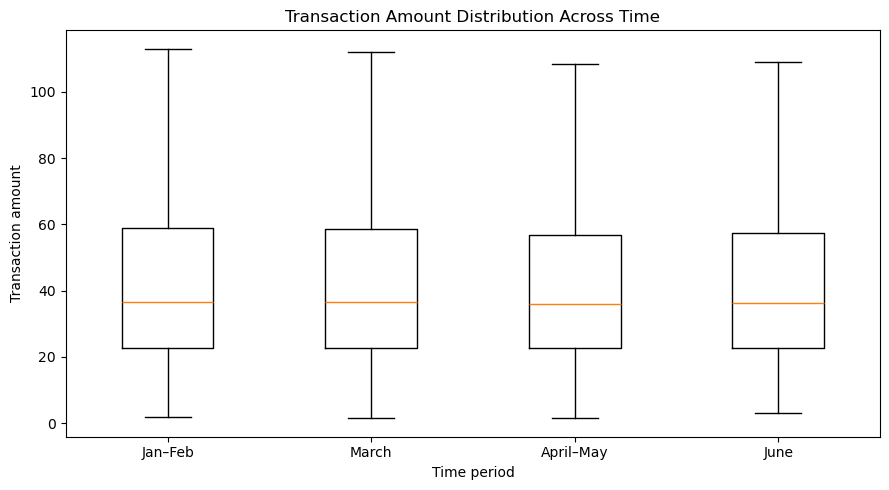

In [57]:
amounts_by_phase = [
    df.loc[
        df["drift_phase_name"] == phase,
        "transaction_amount"
    ]
    for phase in phase_order
]

plt.figure(figsize=(9, 5))

plt.boxplot(amounts_by_phase, showfliers=False)
plt.xticks(
    [1, 2, 3, 4],
    ["Jan–Feb", "March", "April–May", "June"]
)

plt.title("Transaction Amount Distribution Across Time")
plt.xlabel("Time period")
plt.ylabel("Transaction amount")
plt.tight_layout()
plt.show()

In [58]:
channel_percentages = pd.crosstab(
    df["drift_phase_name"],
    df["transaction_channel"],
    normalize="index"
).reindex(phase_order).mul(100)

channel_percentages.round(2)



transaction_channel,ATM,POS,ecommerce,mobile_app,recurring
drift_phase_name,,,,,
stable_training,6.91,41.80,29.35,16.64,5.29
pre_drift_validation,7.16,41.58,29.41,16.60,5.25
peak_drift,6.74,42.11,29.69,16.38,5.08
partial_stabilization,6.68,41.71,29.37,17.09,5.15


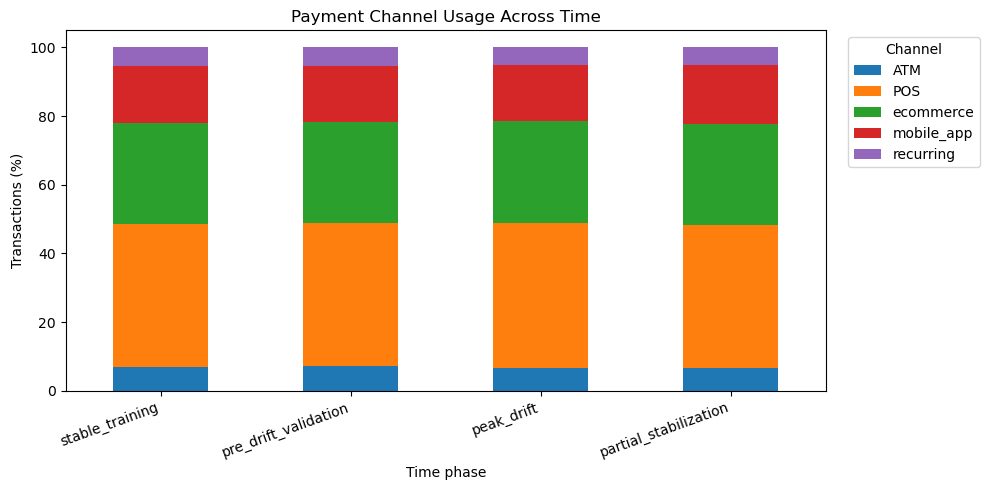

In [59]:
channel_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Payment Channel Usage Across Time")
plt.xlabel("Time phase")
plt.ylabel("Transactions (%)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Channel", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [60]:
y_train_multiclass = train_df["fraud_type"].copy()
y_validation_multiclass = validation_df["fraud_type"].copy()
y_test_multiclass = test_df["fraud_type"].copy()

print("Training examples per category:")
print(y_train_multiclass.value_counts())

Training examples per category:
fraud_type
Legitimate            35416
Card-Not-Present        963
Account-Takeover        813
Synthetic-Identity      674
Friendly-Fraud          657
Card-Present            610
Name: count, dtype: int64


In [61]:
multiclass_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

multiclass_model.fit(X_train, y_train_multiclass)

print("Multiclass Random Forest training completed.")

Multiclass Random Forest training completed.


In [62]:
multiclass_validation_predictions = multiclass_model.predict(
    X_validation
)

print(classification_report(
    y_validation_multiclass,
    multiclass_validation_predictions,
    digits=3,
    zero_division=0
))

                    precision    recall  f1-score   support

  Account-Takeover      0.991     0.995     0.993       429
  Card-Not-Present      0.858     0.980     0.915       501
      Card-Present      0.992     1.000     0.996       355
    Friendly-Fraud      0.986     0.908     0.945       304
        Legitimate      0.999     1.000     0.999     18540
Synthetic-Identity      0.971     0.734     0.836       316

          accuracy                          0.994     20445
         macro avg      0.966     0.936     0.947     20445
      weighted avg      0.994     0.994     0.994     20445



In [63]:
class_names = multiclass_model.named_steps["classifier"].classes_

multiclass_confusion = pd.DataFrame(
    confusion_matrix(
        y_validation_multiclass,
        multiclass_validation_predictions,
        labels=class_names
    ),
    index=class_names,
    columns=class_names
)

multiclass_confusion.index.name = "Actual"
multiclass_confusion.columns.name = "Predicted"

multiclass_confusion

Predicted,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Legitimate,Synthetic-Identity
Actual,,,,,,
Account-Takeover,427,1,1,0,0,0
Card-Not-Present,2,491,0,1,0,7
Card-Present,0,0,355,0,0,0
Friendly-Fraud,0,1,0,276,27,0
Legitimate,0,0,0,2,18538,0
Synthetic-Identity,2,79,2,1,0,232


In [64]:
multiclass_test_predictions = multiclass_model.predict(X_test)

print("Multiclass Random Forest — April to June test results")

print(classification_report(
    y_test_multiclass,
    multiclass_test_predictions,
    digits=3,
    zero_division=0
))

Multiclass Random Forest — April to June test results
                    precision    recall  f1-score   support

  Account-Takeover      0.985     0.980     0.983      1329
  Card-Not-Present      0.756     0.946     0.840      1415
      Card-Present      0.977     0.997     0.987       933
    Friendly-Fraud      0.969     0.896     0.931       932
        Legitimate      0.998     1.000     0.999     54657
Synthetic-Identity      0.923     0.616     0.739      1156

          accuracy                          0.989     60422
         macro avg      0.935     0.906     0.913     60422
      weighted avg      0.990     0.989     0.989     60422



In [65]:
multiclass_monthly_results = []

for month, group in test_df.groupby("month"):
    predictions = multiclass_model.predict(group[feature_columns])

    report = classification_report(
        group["fraud_type"],
        predictions,
        labels=class_names,
        output_dict=True,
        zero_division=0
    )

    multiclass_monthly_results.append({
        "Month": month,
        "Macro F1": report["macro avg"]["f1-score"],
        "Synthetic-Identity recall":
            report["Synthetic-Identity"]["recall"],
        "Card-Not-Present precision":
            report["Card-Not-Present"]["precision"]
    })

multiclass_monthly_results = pd.DataFrame(
    multiclass_monthly_results
)

multiclass_monthly_results.round(4)

,Month,Macro F1,Synthetic-Identity recall,Card-Not-Present precision
0,4,0.9128,0.5866,0.7360
1,5,0.9099,0.6231,0.7639
2,6,0.9166,0.6388,0.7687


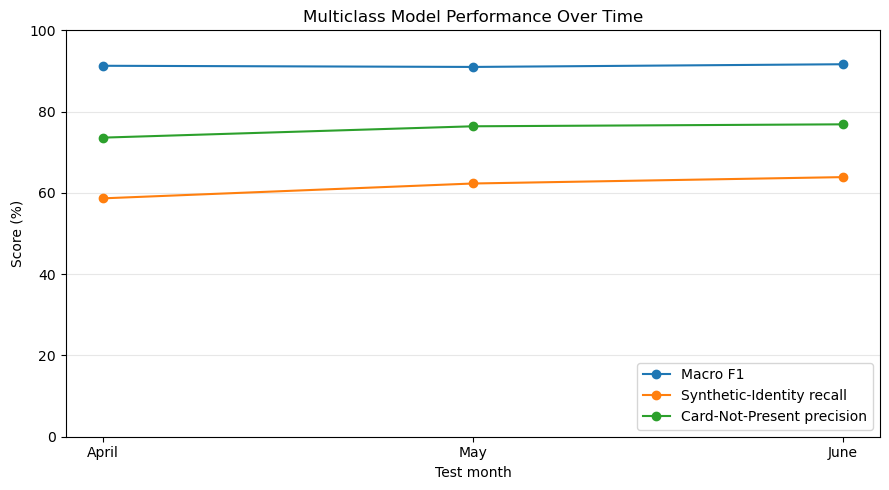

In [66]:
plot_data = multiclass_monthly_results.set_index("Month")

plot_data.mul(100).plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("Multiclass Model Performance Over Time")
plt.xlabel("Test month")
plt.ylabel("Score (%)")
plt.xticks([4, 5, 6], ["April", "May", "June"])
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [67]:
from pathlib import Path

results_folder = Path("results")
results_folder.mkdir(exist_ok=True)

comparison.to_csv(
    results_folder / "binary_model_comparison.csv",
    index=False
)

monthly_test_results.to_csv(
    results_folder / "binary_monthly_test_results.csv",
    index=False
)

multiclass_monthly_results.to_csv(
    results_folder / "multiclass_monthly_test_results.csv",
    index=False
)

drift_summary.to_csv(
    results_folder / "drift_summary.csv"
)

print("Tables saved in:", results_folder.resolve())

Tables saved in: C:\Users\abinr\Downloads\Credit_Card_Fraud_Detection\results


In [68]:
binary_test_report = pd.DataFrame(
    classification_report(
        y_test,
        test_predictions,
        output_dict=True,
        zero_division=0
    )
).transpose()

multiclass_test_report = pd.DataFrame(
    classification_report(
        y_test_multiclass,
        multiclass_test_predictions,
        output_dict=True,
        zero_division=0
    )
).transpose()

binary_test_report.to_csv(
    results_folder / "binary_test_report.csv"
)

multiclass_test_report.to_csv(
    results_folder / "multiclass_test_report.csv"
)

print("Both test reports saved.")

Both test reports saved.


In [69]:
import joblib

joblib.dump(
    tree_model,
    results_folder / "binary_decision_tree.joblib"
)

joblib.dump(
    multiclass_model,
    results_folder / "multiclass_random_forest.joblib"
)

joblib.dump(
    feature_columns,
    results_folder / "feature_columns.joblib"
)

print("Models and feature list saved.")

Models and feature list saved.


## Findings and limitations
- The dataset has 120,000 transactions from January to June 2026.
  Out of these, 9.49% are fraudulent.

- Among the three binary models I tested, the Decision Tree gave
  the best validation F1-score of 0.9953.

- On the April–June test data, the Decision Tree caught 5,718 fraud
  cases and missed 47. It wrongly flagged 15 genuine transactions.

- Using SMOTENC helped Logistic Regression catch slightly more fraud,
  but it also caused more false alarms. Its precision and F1-score
  dropped, so balancing did not give a better overall result.

- For fraud category prediction, Random Forest scored about 0.947
  macro F1 on validation data and 0.913 on test data.
  Synthetic-Identity was the most difficult category to identify.

- Fraud detection stayed consistent across the test months, but
  predicting the exact fraud type was harder than it was in March.

- I noticed small changes in transaction patterns over time.
  However, these checks are not enough to explain why fraud category
  prediction became weaker.

- I could not confirm how the historical features were calculated.
  They should only use information available before each transaction.
  Good results on this dataset do not guarantee the same performance
  with real-world transactions.

In [ ]:
sample = X_test.iloc[[0]]

prediction = tree_model.predict(sample)[0]
fraud_probability = tree_model.predict_proba(sample)[0, 1]

print("Prediction:", "Fraudulent" if prediction == 1 else "Legitimate")
print("Fraud probability:", round(fraud_probability * 100, 2), "%")
print("Actual label:", "Fraudulent" if y_test.iloc[0] == 1 else "Legitimate")

Prediction: Legitimate
Fraud probability: 0.0 %
Actual label: Legitimate


In [71]:
sample = X_test.loc[y_test == 1].iloc[[0]]

prediction = tree_model.predict(sample)[0]
fraud_probability = tree_model.predict_proba(sample)[0, 1]

print("Prediction:", "Fraudulent" if prediction == 1 else "Legitimate")
print("Fraud probability:", round(fraud_probability * 100, 2), "%")
print("Actual label: Fraudulent")

Prediction: Fraudulent
Fraud probability: 100.0 %
Actual label: Fraudulent
